In [ ]:
from scipy.stats import norm
import numpy as np

np.random.seed(23)
volatilidad_aj = 0.2/np.sqrt(3)

b=0.05
b_a = 0.5*(b-0.5*volatilidad_aj**2)

def bs(S0, K, r, sigma, T, b_a, call_opt=True):
    d1 = (np.log(S0 / K) + (b_a + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    put = K * np.exp(-r * T) * norm.cdf(-d2) - S0 * np.exp((b_a - r)*T) * norm.cdf(-d1)
    call = S0 * np.exp((b_a - r) * T) * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    if call_opt:
        return call
    else:
        return put

call_as_geo = bs(S0=100, K=100, r=0.05, sigma=volatilidad_aj, T=1, b_a=b_a, call_opt=True)
put_as_geo = bs(S0=100, K=100, r=0.05, sigma=volatilidad_aj, T=1, b_a=b_a, call_opt=False)
call_as_geo, put_as_geo 

(np.float64(5.546818633789201), np.float64(3.46333194773856))

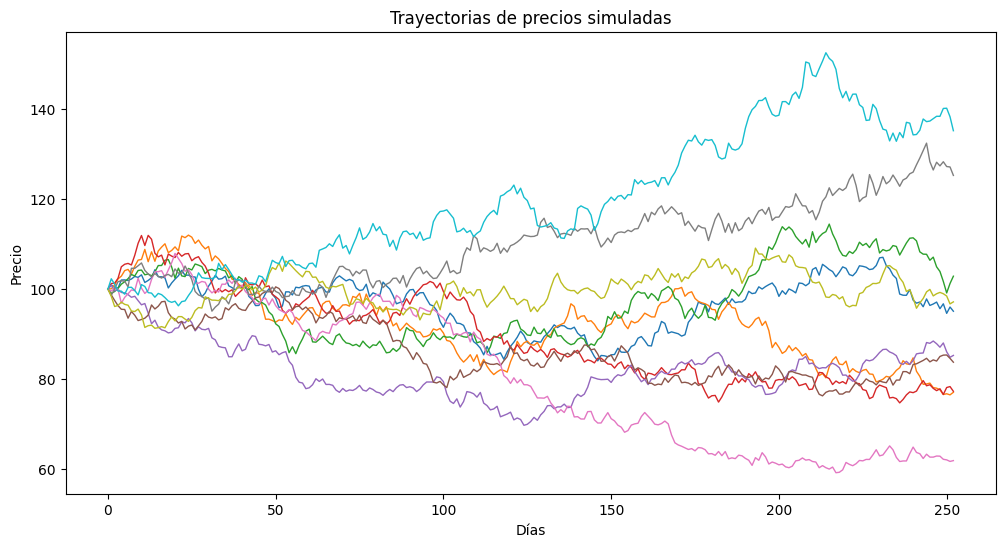

In [30]:
from scipy.stats import gmean
import matplotlib.pyplot as plt

def create_paths(S0, r, sigma, T, steps, n_paths):
    dt = T / steps
    paths = np.zeros((steps + 1, n_paths))
    paths[0, :] = S0
    for t in range(steps):
        paths[t+1, :] = paths[t, :] * np.exp((r - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * np.random.normal(0, 1, n_paths))
    return paths

trayectorias = create_paths(S0=100, r=0.05, sigma=0.2, T=1, steps=252, n_paths=10)

media_arit = np.mean(trayectorias, axis=0)
media_geom = gmean(trayectorias, axis=0)

plt.figure(figsize=(12,6))
for i in range(trayectorias.shape[1]):
    plt.plot(range(trayectorias.shape[0]), trayectorias[:, i], lw=1)
plt.title('Trayectorias de precios simuladas')
plt.xlabel('Días')
plt.ylabel('Precio')
plt.show()

In [31]:
media_geom, media_arit

(array([ 96.67332239,  92.2315109 ,  97.39207097,  88.85025835,
         81.95604666,  86.11569336,  78.84187749, 109.94855373,
         99.72440142, 118.85394941]),
 array([ 96.85324506,  92.61153551,  97.74969019,  89.42105481,
         82.19801044,  86.36669739,  80.41038012, 110.29491479,
         99.79789721, 119.77404029]))

In [32]:
np.mean(media_geom), np.mean(media_arit)

(np.float64(95.05876846732447), np.float64(95.54774658111536))

In [33]:
b_est = np.sum((media_geom - np.mean(media_geom))*(media_arit - np.mean(media_arit))) / np.sum((media_geom - np.mean(media_geom))**2)
b_est

np.float64(0.9949592600237849)

In [ ]:
yi_b = media_arit - b_est * (media_geom - np.mean(media_geom))
yi_b

array([95.24682969, 95.42454161, 95.42814926, 95.59826944, 95.23468483,
       95.26469278, 96.54552597, 95.48018507, 95.15578251, 96.09880467])